In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import datetime as dt
from scipy.stats import linregress
from statsmodels.tsa.seasonal import seasonal_decompose
from google.colab import drive as dr
import seaborn as sns
import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.ticker as ticker
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy import stats
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import matplotlib.patheffects as path_effects
from statsmodels.tsa.seasonal import STL
#from brokenaxes import brokenaxes
from math import pi
from matplotlib.ticker import FormatStrFormatter
import matplotlib as mpl
from matplotlib.patches import Patch
plt.rcParams.update({'font.size': 20,'xtick.labelsize': 20, 'ytick.labelsize': 20,'axes.labelsize': 20,'axes.titlesize': 20,'legend.fontsize': 20}) #일괄 적용

import matplotlib.font_manager as fm

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [ ]:
parent_dr= '/content/drive/MyDrive/cement/'
act_raw= pd.read_csv(parent_dr+'2A1_monthly_activity_paper.csv',encoding ='cp949')
act_raw.head()

act = act_raw.melt(id_vars=['year', 'month'], var_name='SOURCE', value_name='ton')
coastal_set = {'HR-OK', 'SP-SC', 'SS-DH'}
act['Region'] = act['SOURCE'].apply(lambda x: 'Coastal area' if x in coastal_set else 'Inland area')

#check1 #share
nir_2022= 43011 #ton
df_2022 = act[act['year'] == 2022]
val_2022_kt = df_2022['ton'].sum() / 1000
print(f"The study coverage: {val_2022_kt:,.2f} kt")
coverage_ratio = (val_2022_kt/nir_2022) *100
print(f"2022 Annual National Total (from activity data): {val_2022_kt:,.2f} kt")
print(f"Coverage compared to NIR 2022: {coverage_ratio:.1f}%")

#check2 #composition
region_sums = df_2022.groupby('Region')['ton'].sum() / 1000
coastal_ratio_of_nir = (region_sums['Coastal area'] / nir_2022) * 100
inland_ratio_of_nir = (region_sums['Inland area'] / nir_2022) * 100
total_coverage_of_nir = coastal_ratio_of_nir + inland_ratio_of_nir
print(f"--- 2022 NIR ({nir_2022} kt) ---")
print(f"Coastal Area: {coastal_ratio_of_nir:.1f}%")
print(f"Inland Area:  {inland_ratio_of_nir:.1f}%")
print(f"Total Analyzed Coverage: {total_coverage_of_nir:.1f}%")



The study coverage: 42,287.08 kt
2022 Annual National Total (from activity data): 42,287.08 kt
Coverage compared to NIR 2022: 98.3%
--- 2022 NIR (43011 kt) ---
Coastal Area: 49.7%
Inland Area:  48.6%
Total Analyzed Coverage: 98.3%


# [1] historical emission 2016 ~ 2023

In [ ]:
ef = 0.5295; ckkd = 1.02
act['emission'] = act['ton'] * ef * ckkd #tonCO2
act['kt'] = act['emission']/1e3
act['mt'] = act['emission']/1e6
act.head()
code_mapping = {'SP-SC': 'C2', 'SS-DH': 'C1', 'HR-OK': 'C3','SS-DY': 'L1', 'HL-DY': 'L2', 'HH-SG': 'L3','AS-JC':'L4','SS-YW':'L5','HH-YW':'L6'}
act['code'] = act['SOURCE'].map(code_mapping)
act['date'] = pd.to_datetime(act[['year', 'month']].assign(day=1))
act.tail()

,year,month,SOURCE,ton,Region,emission,kt,mt,code,date
859,2023,8,HR-OK,365280.0,Coastal area,197284.07520,197.284075,0.197284,C3,2023-08-01
860,2023,9,HR-OK,401098.0,Coastal area,216629.01882,216.629019,0.216629,C3,2023-09-01
861,2023,10,HR-OK,419541.0,Coastal area,226589.89869,226.589899,0.226590,C3,2023-10-01
862,2023,11,HR-OK,472748.0,Coastal area,255326.46732,255.326467,0.255326,C3,2023-11-01
863,2023,12,HR-OK,377237.0,Coastal area,203741.93133,203.741931,0.203742,C3,2023-12-01


In [ ]:
act.groupby(['year','Region'])['mt'].sum()

year  Region      
2016  Coastal area    13.158748
      Inland area     13.004823
2017  Coastal area    13.326959
      Inland area     12.558994
2018  Coastal area    12.498296
      Inland area     11.614086
2019  Coastal area    13.005780
      Inland area     11.409680
2020  Coastal area    11.740793
      Inland area     10.524969
2021  Coastal area    11.911743
      Inland area     11.201633
2022  Coastal area    11.540951
      Inland area     11.297880
2023  Coastal area    11.746745
      Inland area     10.750237
Name: mt, dtype: float64

# Figure1

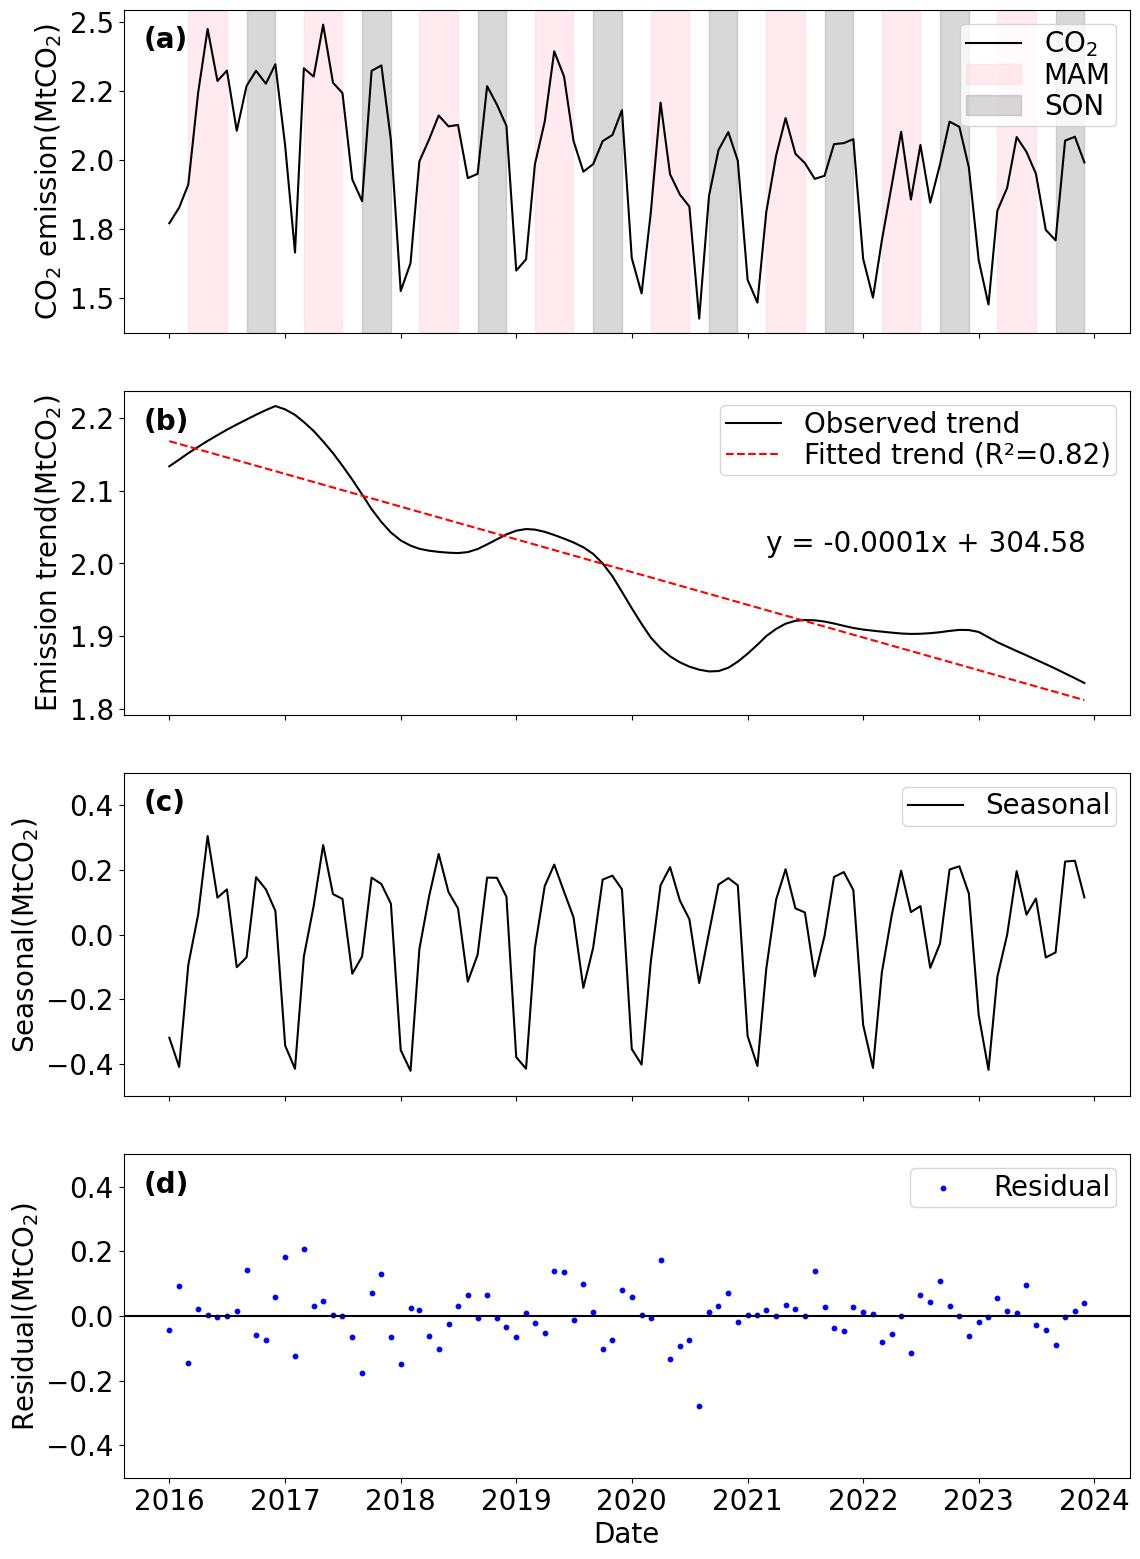

In [ ]:
#totArea
c= act.groupby(['date','year','month'])['mt'].sum().reset_index()
c['date'] = pd.to_datetime(c['date'])
c = c.set_index("date")
stl = STL(c['mt'], period=12)
result = stl.fit()

# 2. Trend + regression 및 R²
valid_idx = ~np.isnan(result.trend)
valid_dates = result.trend.index[valid_idx]
valid_trend = result.trend[valid_idx]

#Plot1
fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

line,= axes[0].plot(c['mt'], label='CO$_2$', color='black')
for year in c.index.year.unique():
    axes[0].axvspan(pd.Timestamp(f"{year}-03-01"), pd.Timestamp(f"{year}-06-30"), color='pink', alpha=0.3)
    axes[0].axvspan(pd.Timestamp(f"{year}-09-01"), pd.Timestamp(f"{year}-11-30"), color='grey', alpha=0.3)
axes[0].set_ylabel("CO$_2$ emission(MtCO$_2$)")
#axes[0].legend()
grey_patch = mpatches.Patch(color='pink', alpha=0.3, label='MAM')
blue_patch = mpatches.Patch(color='grey', alpha=0.3, label='SON')
axes[0].legend(handles=[line, grey_patch, blue_patch], loc='upper right',labelspacing=0.1, borderpad=0.2)
axes[0].yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

#Plot2 trend_line
def add_trend_line(ax, x, y):
    julian_x = x.to_julian_date()
    slope, intercept, r_value, _, _ = linregress(julian_x, y)
    ax.plot(x, slope * julian_x + intercept, color='red', linestyle='dashed', label=f'Fitted trend (R²={r_value**2:.2f})')
    ax.legend()
axes[1].plot(valid_dates, valid_trend, label='Observed trend', color='black')
if len(valid_trend) > 1:
    x_julian = valid_dates.to_julian_date()
    slope, intercept, r_value, _, _ = linregress(x_julian, valid_trend)

    if not np.isnan(slope) and not np.isnan(r_value):
        axes[1].plot(valid_dates, slope * x_julian + intercept, color='red', linestyle='dashed', label=f'Fitted trend (R²={r_value**2:.2f})')
        eq_text = f"y = {slope:.4f}x + {intercept:.2f}"
        axes[1].annotate(eq_text, xy=(valid_dates[int(len(valid_dates)*0.65)], valid_trend.max()-0.2), color='black')
axes[1].set_ylabel("Emission trend(MtCO$_2$)")
axes[1].legend(loc='upper right',labelspacing=0.1, borderpad=0.2)
axes[1].tick_params(axis='y')
axes[1].tick_params(axis='x')

#Plot3 Seasonality
axes[2].plot(result.seasonal, label='Seasonal', color='black')
axes[2].set_ylabel("Seasonal(MtCO$_2$)")
axes[2].legend(loc='upper right',labelspacing=0.1, borderpad=0.2)
axes[2].tick_params(axis='y')
axes[2].tick_params(axis='x')
axes[2].set_ylim(-0.5, 0.5)

#Plot4
axes[3].scatter(c.index, result.resid, label='Residual', color='blue', s=10)
axes[3].axhline(y=0, linestyle="-", color="black")
axes[3].set_ylabel('Residual(MtCO$_2$)')
axes[3].legend(loc='upper right',labelspacing=0.1, borderpad=0.2)
axes[3].set_ylim(-0.5, 0.5)

axes[0].text(0.02, 0.95, "(a)", transform=axes[0].transAxes, fontweight='bold', va='top')
axes[1].text(0.02, 0.95, "(b)", transform=axes[1].transAxes, fontweight='bold', va='top')
axes[2].text(0.02, 0.95, "(c)", transform=axes[2].transAxes, fontweight='bold', va='top')
axes[3].text(0.02, 0.95, "(d)", transform=axes[3].transAxes, fontweight='bold', va='top')
plt.xlabel('Date')
plt.tight_layout()
#plt.savefig(parent_dr+'/png/fig2.png', dpi=300, bbox_inches='tight')

# Figure2

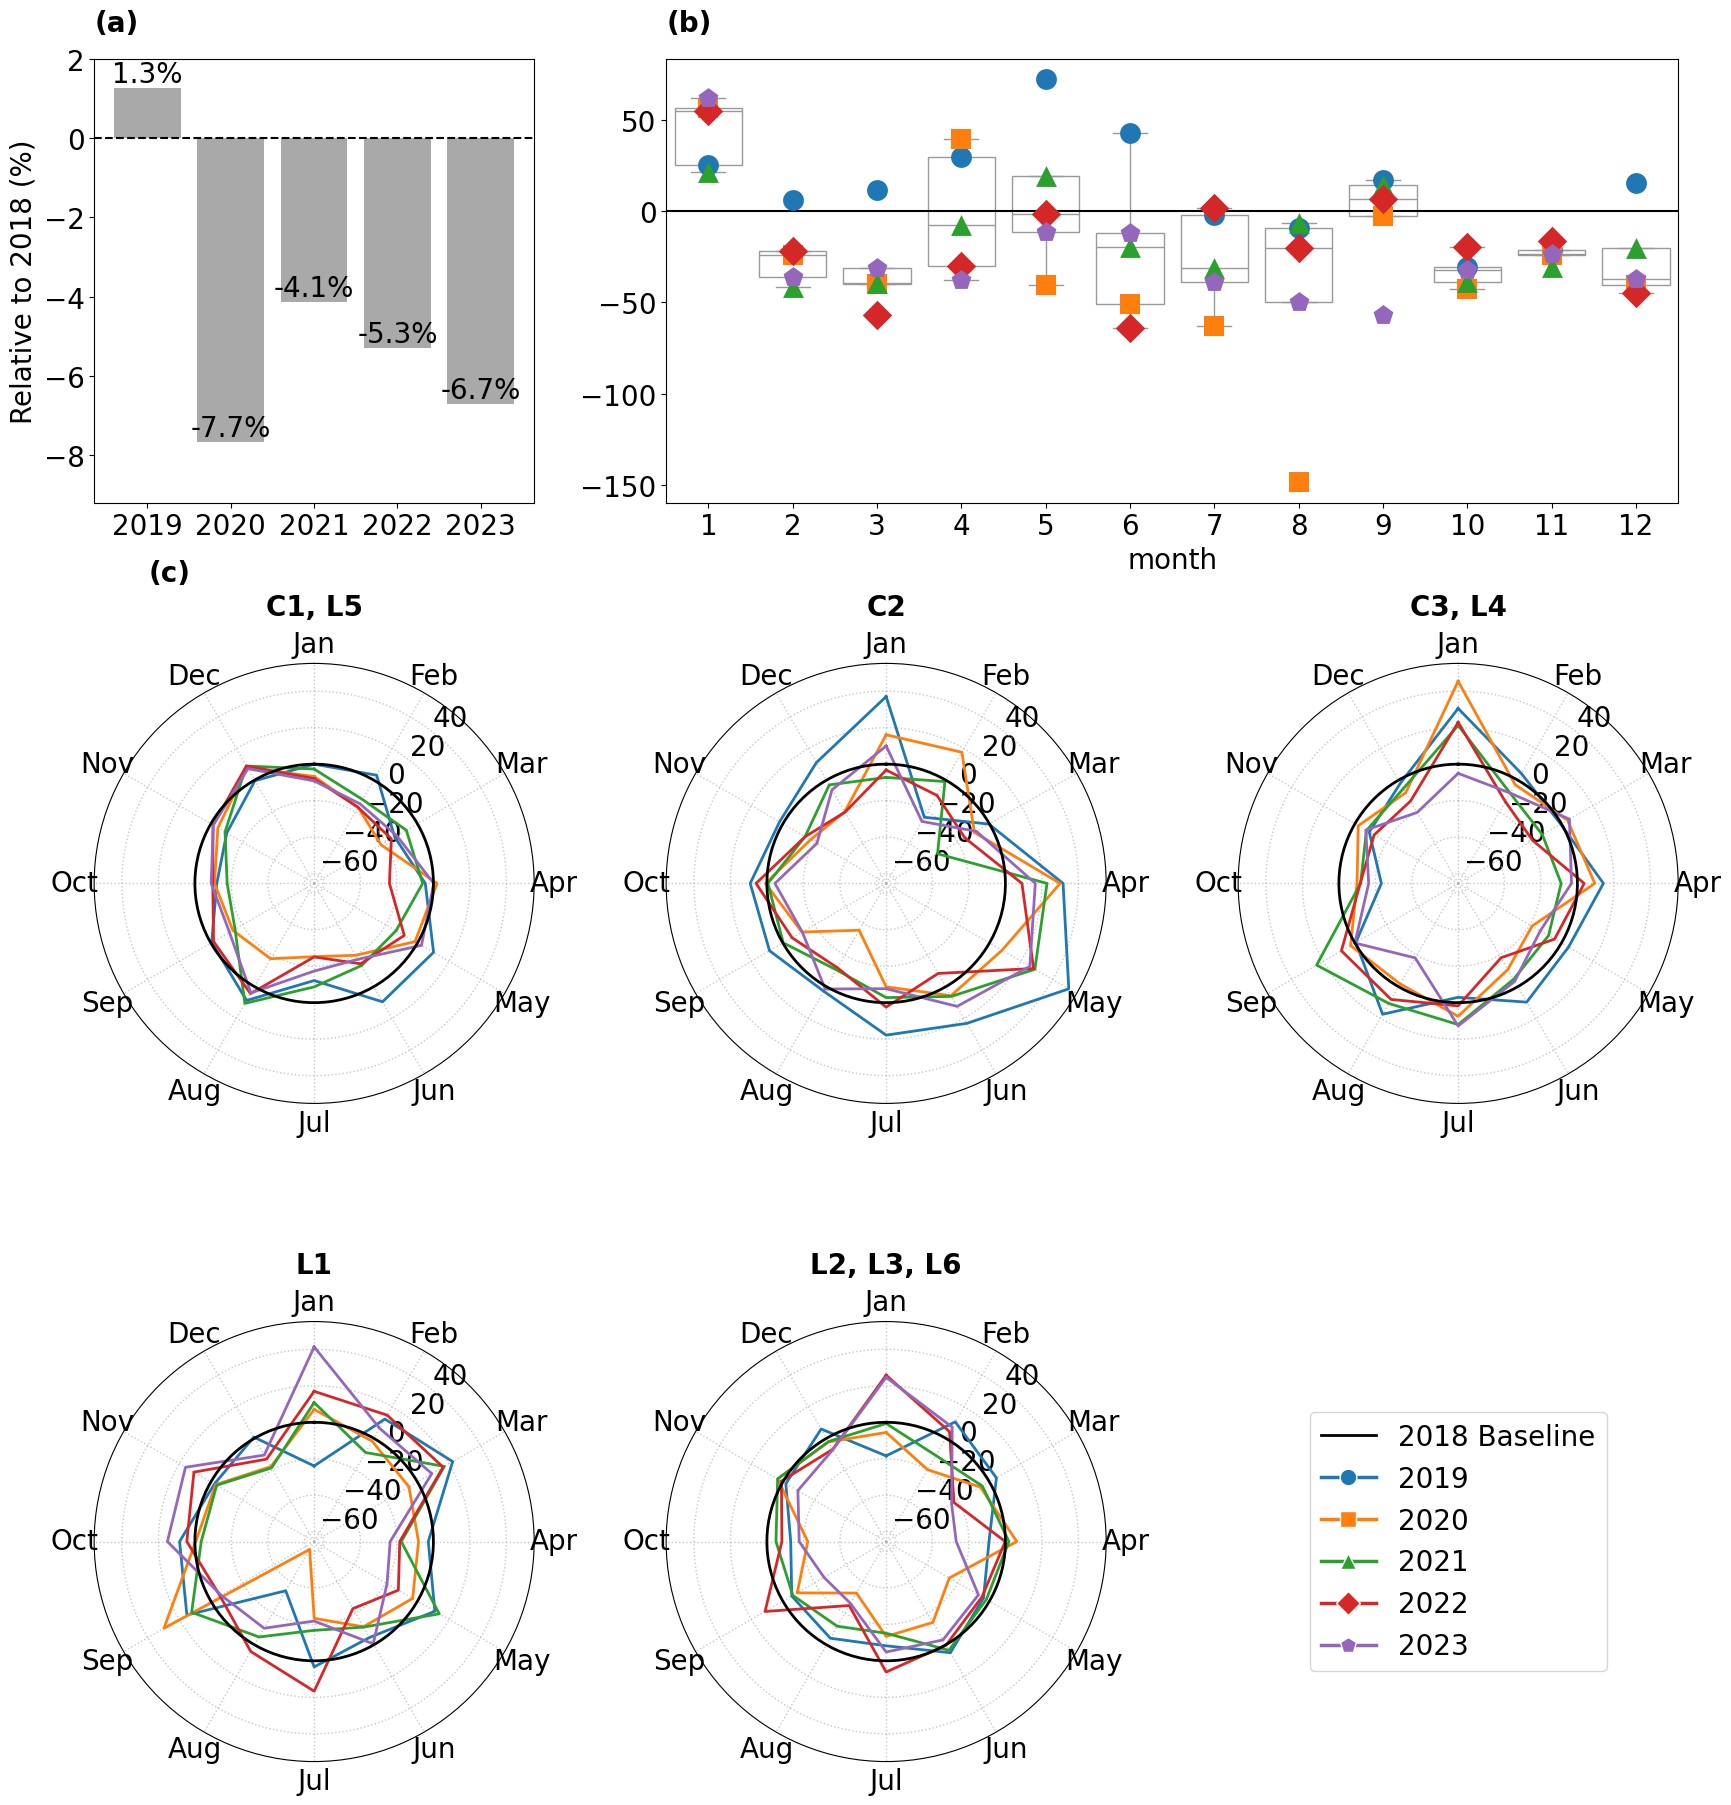

In [ ]:
S=20
com = act.copy()
com['code'] = com['code'].replace({'L5': 'C1', 'L3':'L2', 'L6':'L2', 'L4':'C3'})
com_grp = com.groupby(['date','code','year','month'])['mt'].sum().reset_index()

base2018 = com_grp[com_grp['year'] == 2018].copy()
base2018 = base2018.rename(columns={'mt': 'mt_2018','date':'date_2018','year':'2018'})

merged_df = com_grp.merge(base2018, on=['code', 'month'], how='left')
targetPeriod = merged_df.query("2019 <= year <= 2023").copy()
targetPeriod['reduction'] = targetPeriod['mt'] - targetPeriod['mt_2018']
targetPeriod['percent'] = (targetPeriod['reduction'] / targetPeriod['mt_2018']) * 100

yearsum = targetPeriod.groupby(['year'])[['mt', 'mt_2018']].sum().reset_index()
yearsum['reduction'] = yearsum['mt'] - yearsum['mt_2018']
yearsum['percent'] = (yearsum['reduction'] / yearsum['mt_2018']) * 100


fig = plt.figure(figsize=(18, 20))
gs = fig.add_gridspec(3, 3, height_ratios=[1.2, 1.5, 1.5], width_ratios=[1, 1, 1], hspace=0.2, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1:])


radar_axes = [fig.add_subplot(gs[i, j], projection='polar') for i in range(1, 3) for j in range(3)]
fig.text(0.1, 0.68, "(c)",  fontweight='bold', va='top', ha='left')
#Plot 1 (a)
bars = ax1.bar(yearsum['year'], yearsum['percent'], color='darkgray')
for bar, percent in zip(bars, yearsum['percent']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{percent:.1f}%', ha='center', va='bottom')
ax1.set_ylabel('Relative to 2018 (%)',fontsize=S)
ax1.set_ylim(yearsum['percent'].min() * 1.2, 2)
ax1.axhline(y=0, linestyle='--', color='black')
ax1.set_xticks(yearsum['year'])
ax1.set_title('(a)', loc='left', pad=S, fontweight='bold') #yearly Total Reduction
ax1.tick_params(axis='both', labelsize=S)


#Plot 2 (b)
comsum = targetPeriod.groupby(['date', 'year', 'month'])['percent'].sum().reset_index()
sns.boxplot(ax=ax2, x='month', y='percent', data=comsum, color='white')
unique_years = sorted(comsum['year'].unique())
marker_dict = ['o', 's', '^', 'D', 'p']
color_dict = sns.color_palette("tab10", len(unique_years))

for i, year in enumerate(unique_years):
    sns.swarmplot(ax=ax2, data=comsum[comsum['year'] == year], x='month', y='percent',
                  marker=marker_dict[i % len(marker_dict)], color=color_dict[i % len(color_dict)], s=S-5)
ax2.set_title('(b)', loc='left', pad=S, fontweight='bold') #Monthly distributions
ax2.tick_params(axis='both', labelsize=S)
ax2.axhline(y=0, linestyle='-', color='black')
ax2.set_ylabel(' ')
if ax2.get_legend():
    ax2.get_legend().remove()

#Plot 3 (c)
def radar_factory(num_vars):
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]
    return angles

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
categories = targetPeriod.code.unique()
custom_labels = {"C1": "C1, L5", "C2": "C2", "C3": "C3, L4", "L1": "L1", "L2": "L2, L3, L6"}

N = 12
angles = radar_factory(N)
radar_handles = []
radar_labels = []
baseline_handle = None

for i, cat in enumerate(categories):
    ax = radar_axes[i]
    df_cat = targetPeriod[targetPeriod['code'] == cat]
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.grid(True, linestyle=':', linewidth=1, alpha=0.7)
    ax.set_rlabel_position(38)
    ax.yaxis.set_label_coords(-0.15, 0.5)

    # Baseline
    b_line, = ax.plot(np.linspace(0, 2*np.pi, 100), np.zeros(100), color='black', linewidth=2, zorder=10)
    if i == 0: baseline_handle = b_line
    for j, year in enumerate(unique_years):
        df_year = df_cat[df_cat['year'] == year].groupby('month')['percent'].mean().reindex(range(1, 13), fill_value=0)
        values = df_year.values.tolist() + df_year.values[:1].tolist()
        line, = ax.plot(angles, values, color=color_dict[j], linewidth=2)
        if i == 0:
            radar_handles.append(line)
            radar_labels.append(str(year))

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(months, fontsize=S)
    ax.tick_params(axis='y',pad=3)
    ax.set_title(custom_labels.get(cat, cat), pad=35, fontweight='bold', fontsize=S)
    ax.set_ylim(targetPeriod['percent'].min()-5, targetPeriod['percent'].max()+5) # 모든 그래프의 scale 통일

#Legend
for j in range(len(categories), len(radar_axes)):
    radar_axes[j].axis('off')
final_handles = []; final_labels = []
if baseline_handle:
    b_handle = Line2D([0], [0], color='black', linewidth=2, linestyle='-', label="2018 Baseline")
    final_handles.append(b_handle)
    final_labels.append("2018 Baseline")
for i, year in enumerate(unique_years):
    combined_handle = Line2D([0], [0],color=color_dict[i % len(color_dict)], ls='-', lw=2.5,
                             marker=marker_dict[i % len(marker_dict)],
                             markerfacecolor=color_dict[i % len(color_dict)],
                             markeredgecolor='white', markersize=12, label=str(year))
    final_handles.append(combined_handle)
    final_labels.append(str(year))
radar_axes[-1].legend(handles=final_handles,labels=final_labels,loc='center',
                      ncol=1,fontsize=S, frameon=True, title_fontsize=S)
plt.subplots_adjust(left=0.07, right=0.95, bottom=0.05, top=0.93, hspace=0.2, wspace=0.5)
#plt.savefig(parent_dr+'/png/fig3.png',dpi=300, bbox_inches='tight')
plt.show()

# Figure 3

#Figure3 _Yearly

In [ ]:
sce_raw= pd.read_csv(parent_dr+'default_scen.csv',encoding ='cp949')
sce_raw.head()

,year,month,region,ton,ef_used,emission,kt,mt,date,scenario
0,2018,1,Coastal area,1621846.0,0.5295,8.759428e+05,875.942806,0.875943,2018-01-01,S1
1,2018,1,Inland area,1202732.0,0.5295,6.495835e+05,649.583526,0.649584,2018-01-01,S1
2,2018,2,Coastal area,1699114.0,0.5295,9.176745e+05,917.674480,0.917674,2018-02-01,S1
3,2018,2,Inland area,1312752.0,0.5295,7.090042e+05,709.004228,0.709004,2018-02-01,S1
4,2018,3,Coastal area,1880210.0,0.5295,1.015483e+06,1015.482619,1.015483,2018-03-01,S1


# Figure4

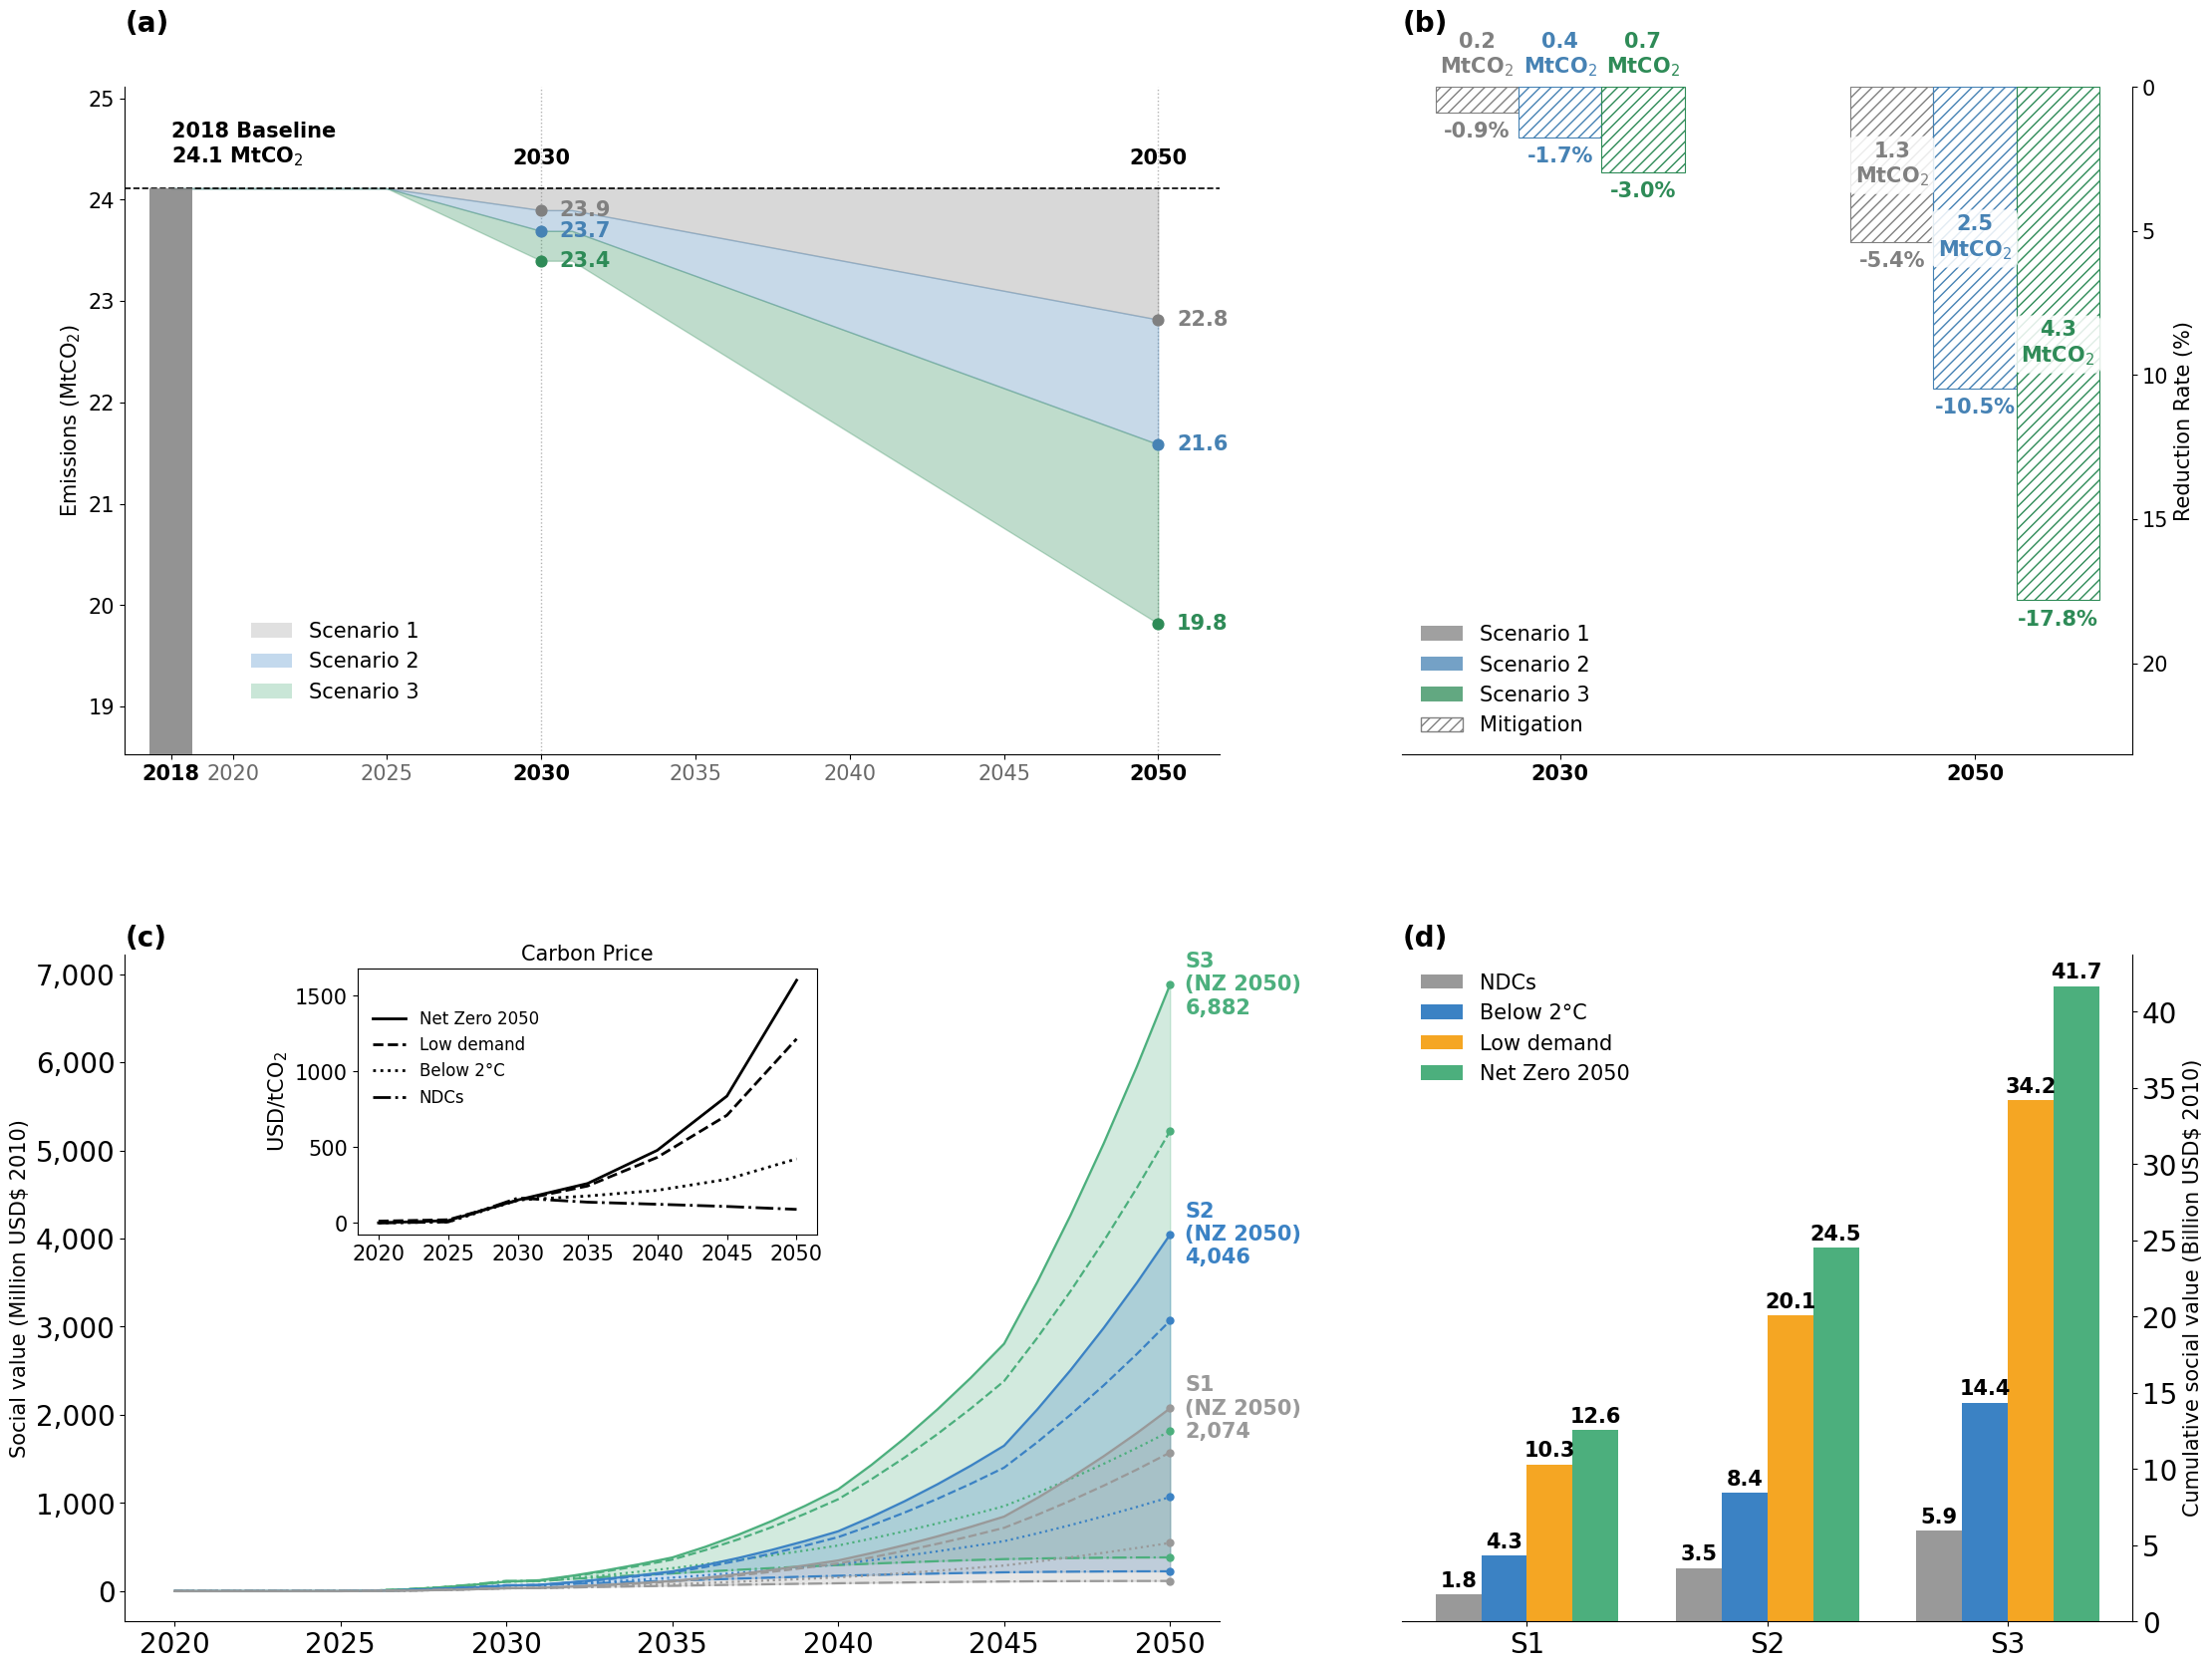

In [ ]:
FIGSIZE = (26, 20)
REF_SIZE = (26, 20)
scale = ((FIGSIZE[0] / REF_SIZE[0]) + (FIGSIZE[1] / REF_SIZE[1])) / 2

def FS(base):
    return round(base * scale, 1)

fig = plt.figure(figsize=FIGSIZE)
gs_main = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.3) # Adjusted row for legends and adjusted hspace
gs_top = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_main[0], width_ratios=[3, 2], wspace=0.2)
ax  = fig.add_subplot(gs_top[0])
ax2 = fig.add_subplot(gs_top[1])
gs_bot = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_main[1], width_ratios=[3, 2], wspace=0.2) # Changed index to 1
ax3       = fig.add_subplot(gs_bot[0])
ax3_right = fig.add_subplot(gs_bot[1])

scen_color = {'S1': 'gray', 'S2': 'steelblue', 'S3': 'seagreen'}

# (a) Emission pathways — 2018 bar only, then line + band
annual = sce_raw.groupby(['scenario', 'year'])['emission'].sum().reset_index()
a1 = annual[annual['scenario'] == 'S1'].sort_values('year').reset_index(drop=True)
a2 = annual[annual['scenario'] == 'S2'].sort_values('year').reset_index(drop=True)
a3 = annual[annual['scenario'] == 'S3'].sort_values('year').reset_index(drop=True)
base_emission = a1.loc[a1['year'] == 2018, 'emission'].values[0]
baseline_mt = base_emission / 1e6
a1['mt'] = a1['emission'] / 1e6
a2['mt'] = a2['emission'] / 1e6
a3['mt'] = a3['emission'] / 1e6

scen_info = {'S1': (scen_color['S1'], a1, 'Scenario 1'),
             'S2': (scen_color['S2'], a2, 'Scenario 2'),
             'S3': (scen_color['S3'], a3, 'Scenario 3')}

ax.bar(2018, baseline_mt, width=1.4, color='gray', alpha=0.85, zorder=4)
#ax.plot([2018, 2018], [baseline_mt, baseline_mt + 1.0], color='black', linewidth=1)
ax.text(2018, baseline_mt + 0.2, f'2018 Baseline\n{baseline_mt:.1f} MtCO$_2$',
        ha='left', va='bottom', fontsize=FS(15), fontweight='bold', color='black')
years_line = a1['year'].values
ax.fill_between(years_line, baseline_mt, a1['mt'], color='gray', alpha=0.3, zorder=1)
ax.fill_between(years_line, a1['mt'], a2['mt'], color='steelblue', alpha=0.3, zorder=1)
ax.fill_between(years_line, a2['mt'], a3['mt'], color='seagreen', alpha=0.3, zorder=1)

for yr in [2030, 2050]:
    ax.axvline(yr, color='dimgray', linestyle=':', linewidth=1.0, alpha=0.5, zorder=0)
    for sname, (color, df_s, label) in scen_info.items():
        val = df_s.loc[df_s['year'] == yr, 'mt'].values[0]
        ax.scatter(yr, val, color=color, s=60 * scale, zorder=5)
        ax.text(yr + 0.6, val, f"{val:.1f}", color=color, fontsize=FS(15),
                      fontweight='bold', va='center', ha='left', zorder=5)
    ax.annotate(f"{yr}",xy=(yr, baseline_mt), xytext=(yr, baseline_mt + 0.2),
        ha='center', va='bottom', fontsize=FS(15), fontweight='bold',)
        #bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='none'),zorder=6)
ax.set_xlim(2016.5, 2052)
ax.set_ylim(baseline_mt - (baseline_mt - scen_info['S3'][1]['mt'].min()) * 1.3, baseline_mt + 1)
xticks_a = [2018, 2020, 2025, 2030, 2035, 2040, 2045, 2050]
ax.set_xticks(xticks_a)
ax.set_xticklabels([str(y) for y in xticks_a])
for tick, yr in zip(ax.get_xticklabels(), xticks_a):
    if yr in [2018, 2030, 2050]:
        tick.set_fontweight('bold'); tick.set_fontsize(FS(15)); tick.set_color('black')
    else:
        tick.set_fontsize(FS(15)); tick.set_color('dimgray')
ax.tick_params(axis='y', labelsize=FS(15))
ax.set_ylabel('Emissions (MtCO$_2$)', fontsize=FS(15))
ax.set_xlabel(' ')
# ax.legend(loc='lower left', fontsize=FS(15), frameon=True, framealpha=0.9) # REMOVED: Conflicting generic legend
ax.set_title('(a)', loc='left', fontsize=FS(20), fontweight='bold', pad=40)
ax.spines[['top','right']].set_visible(False) # Remove top and right spines
ax.axhline(baseline_mt, color='black', linestyle='--', linewidth=1.2)
#Emission pathways under different mitigation scenarios

# (b) Reduction rate char
scenarios_label = ['S1', 'S2', 'S3']
colors_list = [scen_color[s] for s in scenarios_label]
reduction_rate = {};
for sname, (color, df_s, label) in scen_info.items():
    red2030 = baseline_mt - df_s.loc[df_s['year']==2030, 'mt'].values[0]
    red2050 = baseline_mt - df_s.loc[df_s['year']==2050, 'mt'].values[0]
    r2030 = red2030 / baseline_mt * 100
    r2050 = red2050 / baseline_mt * 100
    reduction_rate[sname] = {'2030': r2030, '2050': r2050,'2030_mt': red2030, '2050_mt': red2050}

x2 = [0, 1]
bar_w2 = 0.2
offsets2 = [-bar_w2, 0, bar_w2]
max_rate_2030 = max(reduction_rate[s]['2030'] for s in scenarios_label)
label_y_2030 = -0.3
for i, (sname, color) in enumerate(zip(scenarios_label, colors_list)):
    rates = [reduction_rate[sname]['2030'], reduction_rate[sname]['2050']]
    mts   = [reduction_rate[sname]['2030_mt'], reduction_rate[sname]['2050_mt']]
    for j, (xpos, rate, mt) in enumerate(zip(x2, rates, mts)):
        bx2 = xpos + offsets2[i]
        ax2.bar(bx2, rate, width=bar_w2, color='white', alpha=0.75, zorder=3)
        ax2.bar(bx2, rate, width=bar_w2, color='none', edgecolor=color, hatch='///', linewidth=0.8, zorder=4)
        if j == 0:
            ax2.text(bx2, label_y_2030, f"{mt:.1f}\nMtCO$_2$", ha='center', va='bottom',
                      fontsize=FS(15), color=color, fontweight='bold', zorder=5,
                      bbox=dict(boxstyle='round,pad=0.3', facecolor='none', alpha=0.85, edgecolor='none'))
        else:
            ax2.text(bx2, rate/2, f"{mt:.1f}\nMtCO$_2$", ha='center', va='center',
                      fontsize=FS(15), color=color, fontweight='bold', zorder=5,
                      bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='none'))

        ax2.text(bx2, rate + 1, f"-{rate:.1f}%", ha='center', va='bottom',
                  fontsize=FS(15), color=color, fontweight='bold', zorder=5)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['2030', '2050'], fontsize=FS(15), fontweight='bold')
ax2.tick_params(axis='y', labelsize=FS(15))
ax2.set_ylabel('Reduction Rate (%)', fontsize=FS(15))
ax2.set_ylim(max(reduction_rate['S3']['2050'] * 1.3, 5), 0)
ax2.yaxis.set_label_position('right')
ax2.yaxis.tick_right()
ax2.grid(False) #axis='y', linestyle='--', alpha=0.4)
legend_elements_b = [Patch(facecolor=scen_color['S1'], alpha=0.75, label='Scenario 1'),
                       Patch(facecolor=scen_color['S2'], alpha=0.75, label='Scenario 2'),
                       Patch(facecolor=scen_color['S3'], alpha=0.75, label='Scenario 3'),
                       Patch(facecolor='none', edgecolor='gray', hatch='///', label='Mitigation')]
ax2.legend(handles=legend_elements_b, fontsize=FS(15), loc='lower left', framealpha=0.8, frameon=False)
ax2.set_title('(b)', loc='left', fontsize=FS(20), fontweight='bold', pad=40)
ax2.spines[['top','left']].set_visible(False) # Remove top and right spines

# (c) Social value — Band=scenario (S1/S2/S3), Line style=4 price paths
final = pd.read_csv(parent_dr+'final_cost.csv', encoding='cp949')
# Calculate social_musd inline before drawing (c) and (d)
final['social_musd'] = (final['reduction_t'] * final['carbon_price_usd']) / 1e6
social_annual = final.groupby(['scenario','price_scenario','year'])['social_musd'].sum().reset_index()
scen_color  = {'S1': '#999999', 'S2': '#3B82C4', 'S3': '#4CAF7D'}
sce_label  = {'S1': 'Scenario 1',
               'S2': 'Scenario 2',
               'S3': 'Scenario 3'}
price_style = {'NDCs': '-.', 'Below 2°C': ':', 'Low demand': '--', 'Net Zero 2050': '-'}
price_label = {'NDCs': 'NDCs', 'Below 2°C': 'Below 2°C',
               'Low demand': 'Low demand', 'Net Zero 2050': 'Net Zero 2050'}

social_annual = final.groupby(['scenario','price_scenario','year'])['social_musd'].sum().reset_index()
years_list = sorted(social_annual['year'].unique())
last_yr = years_list[-1]

for sname in ['S3', 'S2', 'S1']:
    sub = social_annual[social_annual['scenario'] == sname]
    pivot = sub.pivot(index='year', columns='price_scenario', values='social_musd').reindex(years_list)
    ax3.fill_between(pivot.index, pivot.min(axis=1), pivot.max(axis=1),
                      color=scen_color[sname], alpha=0.25, zorder=1)
    for ps, ls in price_style.items():
        if ps in pivot.columns:
            ax3.plot(pivot.index, pivot[ps], color=scen_color[sname], linestyle=ls,lw=1.6, zorder=2)
            val = pivot.loc[last_yr, ps]
            ax3.scatter(last_yr, val, color=scen_color[sname], s=25, zorder=3)
            # Adjusted text display logic based on user's request
            if ps == 'Net Zero 2050':
                text_str = f"{sname}\n(NZ 2050)\n{val:,.0f}"
                ax3.text(last_yr + (years_list[-1]-years_list[0])*0.015, val,
                          text_str,fontsize=FS(15), color=scen_color[sname],
                          va='center', fontweight='bold')
ax3.set_xlabel('')
ax3.set_ylabel('Social value (Million USD$ 2010)', fontsize=FS(15))
ax3.set_title('(c)',loc='left', fontsize=FS(20), fontweight='bold')
ax3.spines[['top','right']].set_visible(False)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f'{v:,.0f}'))

# Inset plot for carbon prices
axins = inset_axes(ax3, width="70%", height="100%", loc='upper left', bbox_to_anchor=(0.20, 0.6, 0.6, 0.4), bbox_transform=ax3.transAxes)
carbon_price_annual = final.groupby(['price_scenario', 'year'])['carbon_price_usd'].mean().reset_index()

for ps, ls in price_style.items():
    if ps in carbon_price_annual['price_scenario'].unique():
        data = carbon_price_annual[carbon_price_annual['price_scenario'] == ps]
        axins.plot(data['year'], data['carbon_price_usd'], linestyle=ls, lw=2, color='black') # REMOVED label=price_label[ps]

axins.set_title('Carbon Price', fontsize=FS(15))
axins.tick_params(axis='both', which='major', labelsize=FS(15))
axins.set_ylabel('USD/tCO$_2$', fontsize=FS(15))
#axins.legend(fontsize=FS(15), loc='upper left', frameon=False) # This line was commented out
axins.grid(False) #True, linestyle='--', alpha=0.6)


style_handles = [mlines.Line2D([], [], color='black', linestyle=ls, lw=2, label=price_label[ps])
                  for ps, ls in price_style.items()][::-1]
band_handles  = [Patch(facecolor=scen_color[s], alpha=0.3, label=sce_label[s])
                  for s in ['S1','S2','S3']] # Changed order to S1, S2, S3

# NEW: Price Scenarios legend inside axins
axins.legend(handles=style_handles, loc='upper left', bbox_to_anchor=(0.0, 0.9), fontsize=FS(12), frameon=False, ncol=1)

# NEW: Mitigation Potential legend inside ax (subplot a)
ax.legend(handles=band_handles, loc='lower left', bbox_to_anchor=(0.098, 0.05), fontsize=FS(15), frameon=False, ncol=1)

# REMOVED global legends:
# fig.legend(handles=style_handles, loc='lower center', bbox_to_anchor=(0.25, 0.4), fontsize=FS(15), frameon=True, ncol=2, title='Price Scenarios', title_fontsize=FS(15))
# fig.legend(handles=band_handles, loc='lower center', bbox_to_anchor=(0.75, 0.4), fontsize=FS(15), frameon=True, ncol=2, title='Mitigation Potential', title_fontsize=FS(15))

# (d) Cumulative social value — Grouped bar for 4 price paths
price_color = {'NDCs': '#999999', 'Below 2°C': '#3B82C4', 'Low demand': '#F5A623', 'Net Zero 2050': '#4CAF7D'}
cum = final.groupby(['scenario','price_scenario'])['social_musd'].sum().reset_index()
cum['cum_billion'] = cum['social_musd'] / 1e3

scen_order  = ['S1','S2','S3']
price_order = ['NDCs','Below 2°C','Low demand','Net Zero 2050']
r = np.arange(len(scen_order))
width = 0.19

bar_pos = {}
for i, ps in enumerate(price_order):
    vals = [cum[(cum['scenario']==s) & (cum['price_scenario']==ps)]['cum_billion'].values[0] for s in scen_order]
    xs = r + (i - 1.5) * width
    ax3_right.bar(xs, vals, width, color=price_color[ps], label=price_label.get(ps, ps))
    for xi_, v in zip(xs, vals):
        ax3_right.text(xi_, v + 0.5, f"{v:.1f}", ha='center', fontsize=FS(15), fontweight='bold')
    bar_pos[ps] = dict(zip(scen_order, xs))
ax3_right.set_xticks(r)
ax3_right.set_xticklabels(['S1','S2','S3'], fontsize=FS(20))
ax3_right.set_ylabel('Cumulative social value (Billion USD$ 2010)', fontsize=FS(15))
ax3_right.set_title('(d)',loc='left', fontsize=FS(20), fontweight='bold')
ax3_right.yaxis.set_label_position('right')
ax3_right.yaxis.tick_right()
ax3_right.spines[['top','left']].set_visible(False) # Remove top and right spines
ax3_right.legend(fontsize=FS(15), frameon=False, loc='upper left')

# Multiplier arrow (based on Net Zero 2050, S1->S2, S2->S3)
nz_x = bar_pos['Net Zero 2050']
nz_val = {s: cum[(cum['scenario']==s) & (cum['price_scenario']=='Net Zero 2050')]['cum_billion'].values[0]
          for s in scen_order}
for s_from, s_to in [('S1','S2'), ('S2','S3')]:
    ratio = nz_val[s_to] / nz_val[s_from]
    y = max(nz_val[s_from], nz_val[s_to]) + 5
    #ax3_right.annotate('', xy=(nz_x[s_to], y), xytext=(nz_x[s_from], y),arrowprops=dict(arrowstyle='->', lw=1.3))
    #ax3_right.text((nz_x[s_from]+nz_x[s_to])/2, y+1.5, f"{ratio:.1f}",ha='center', fontsize=FS(13), fontweight='bold')
plt.tight_layout()
#plt.savefig(parent_dr + '/png/fig4_whatif_scenario.png', dpi=300, bbox_inches='tight')